# Transformer-guided QMC for the random antiferromagnetic LTFIM

Unified-model implementation record and experiment guide — updated 26 October 2026.

**Required final deliverable: one shared ALiBi checkpoint for GFMC across L=2,4,6,8.** The Hamiltonian and geometry are conditioning inputs; evaluation and GFMC must not fine-tune weights or switch to a per-size specialist. The extended specialist campaign was stopped and preserved as reference work. The replacement `shared_accuracy.py` campaign trains one width64/depth4 model with all four sizes contributing before each optimizer update, retaining 24 disorder/field/size contexts. Each validation snapshot is tested with identical weights across every context. See `code/transformer_qmc/SHARED_ACCURACY.md`. Specialist results below are benchmarks and teacher initialization data, not the final GFMC guide.

**Goal:** establish reliable finite-size scaling of the pure ground-state replica overlap, $q_{\rm EA}^2=[\langle q^2\rangle]$, and determine whether the chosen antiferromagnetic ensemble has a spin-glass transition. The final workflow is **physical ensemble → neural VMC → frozen-guide GFMC/PQMC → validated nonlocal path updates → disorder averaging and finite-size scaling**.

**In plain language:** train one transformer on several Kagome sizes and fixed random bond samples; freeze its weights; use it to guide a more accurate ground-state projector. Compare the projected answers across sizes before trying to locate a phase transition. The immediate milestone is measured improvement in overlap accuracy, population dependence, and descendant survival, including neural evaluation cost.

**Updated decision:** use a shared, ALiBi-based autoregressive transformer on **L=2,4,6,8**, with **12,48,108,192 spins**. All four sizes participate in training. The L=2 case also permits exact evaluation. Training runs on AutoDL; exact-state solutions are checks, not training labels.

**Status:** both AutoDL training campaigns completed successfully on 26 October 2026. **Seven fixed-size models finished 800 updates each; the unified ALiBi model finished 4,800 updates and all eight evaluation points.** Final checkpoints, intermediate snapshots, logs, and evaluations have been downloaded locally. All five core tests pass locally and on AutoDL; GPU cross-size updates and checkpoint reload checks passed. Projected ground-state comparisons and convergence qualification remain pending.

Read the quick guide below first. Sections 4–5 explain the shared model and training; section 6 explains the projector; section 9 explains how a transition would be identified. Rydberg distance-dependent interactions and nonlocal path updates remain later extensions.

## Benchmark at a glance

**Extended accuracy campaign launched:** before projection, a width-64/four-block ALiBi model is being trained for two independent branches at each of 192,108,48,12 spins. Each branch gets 8,000 VMC updates at batch512 and 4,000 further low-rate updates at batch1024, initialized by transferring the existing guide's conditional probabilities. The [extended accuracy report](alibi_accuracy_push.ipynb) displays downloaded status, validation curves, and independent final comparisons as they become available. This is ongoing work, not a completed accuracy claim. The projector is not launched by this campaign.

**Larger-size ALiBi refinement completed:** the executed [48-, 108-, and 192-spin report](alibi_larger_sizes.ipynb) contains six completed Hamiltonian-specific ALiBi refinements and independent observable audits. Both seeds lower the energy at every size; E/N is approximately −1.09727, −1.11604, and −1.06935, respectively. The 192-spin raw overlap and connected susceptibility still differ significantly between seeds despite close energies. Unlike L2, these sizes have no exact reference; improved variational energies do not certify ground-state overlap accuracy. All six final checkpoints are saved locally and on AutoDL.

**Update: the 12-spin ALiBi accuracy issue has been mitigated.** See the compact executed report [ALiBi 12-site accuracy](alibi_12site_accuracy.ipynb). Four Hamiltonian-specific ALiBi runs (two shared-initialized and two fresh) all passed the predeclared energy/overlap/connected-susceptibility targets. The selected shared-initialized checkpoint has energy error **9.73×10⁻⁶ per spin**, raw-overlap error **0.071%**, and connected-susceptibility error **0.343%**. The architecture remains ALiBi; training uses sampled VMC gradients. It is a specialized checkpoint for L2, disorder 0, Γ=0.5,h=0.3; performance on other Hamiltonians is unqualified.

The figure below records the **original** mixed-context pilot before refinement, preserving the baseline comparison.

![Fixed-size versus unified benchmark](../data/kagome/transformer_af_dual_v1/benchmark/fixed_vs_unified.png)

All panels use Γ=0.5,h=0.3 and disorder ID 0. Compare energies within each size: different sizes have different quenched samples. The unified pilot gives lower sampled energy at L4/L6; fixed models give lower energy at L2/L8. This comparison uses different training budgets and conditioning, so it does not isolate ALiBi.

**The strongest accuracy check is L2 full enumeration:** exact E₀/N=−1.1119147105; fixed-model E/N=−1.1113143581 (error 0.0006003524/spin); unified E/N=−1.0114555261 (error 0.1004591844/spin). These deterministic network evaluations avoid Monte Carlo sampling error. The fixed model's raw overlap is 0.688307 versus exact 0.681861; the unified model gives 0.302024. Connected susceptibility is 0.062198 (fixed), 0.640420 (unified), and 0.065289 (exact). The shared pilot is not yet accurate enough for physical inference.

AutoDL wall time including evaluation: fixed campaign 292 s for seven models; unified campaign 218 s. Individual fixed runs took approximately 10 s (L2), 19 s (L4), 44 s (L6), and 83 s (L8). These are short pilot budgets. A speedup in converged projected observables has not yet been measured.

Figure and exact benchmark data are in `data/kagome/transformer_af_dual_v1/benchmark/`. Regenerate with `PYTHONPATH=code python3 -B -m transformer_qmc.plot_benchmark`.

## Quick guide: what changes with a unified model?

| Question | Current answer |
|---|---|
| How many networks? | One shared set of trainable weights, switched between Hamiltonian contexts. |
| Why ALiBi? | Relative attention biases replace a learned position table tied to one sequence length. |
| Is ALiBi sufficient? | No. Bond conditioning must also have the same feature width at every size. |
| What is a token? | One three-spin Kagome cell, with eight possible configurations. |
| What is the training data? | New spin configurations sampled from the current network for fixed quenched Hamiltonians; no exact-state labels. |
| What has been demonstrated? | Mathematical/kernel checks and acceptance of multiple sizes. Training quality and QMC convergence remain to be measured. |

### Sizes in the shared training set

| Kagome array | Cell tokens | Spins, N=3L² | Role |
|---|---:|---:|---|
| 2×2 | 4 | 12 | Training diversity and exact reference |
| 4×4 | 16 | 48 | Intermediate-size training and projection |
| 6×6 | 36 | 108 | Main larger-system target |
| 8×8 | 64 | 192 | Largest initial training target |

### Configured first AutoDL campaign

`code/transformer_qmc/unified_experiment.py` defines **24 contexts**: four sizes × two training disorder realizations (IDs 0 and 1) × three field pairs, (Γ,h)=(0.5,0.3), (2,0.3), (0.5,0). Bonds use the working assumption K∈[0.5,1.5], with K₀=1. The same bonds are reused across fields.

Defaults: **4,800 updates, 128 independent autoregressive draws/update, Adam, one training seed (42)**. Every shuffled 24-update block visits each context once: 200 updates/context, or 1,200 updates/size. Energy-per-spin gradients keep the largest system from receiving greater weight solely because its energy is extensive. One update uses a single context; this is a shared-weight mixed-size campaign, not a padded mixed-length batch.

Evaluation uses fresh draws at (Γ,h)=(0.5,0.3), for every size, on training disorder ID 0 and held-out disorder ID 2. Each point uses 16 batches of 128 energy samples and independent four-replica draws. L=2 also receives full-state VMC evaluation and an exact ground-state reference. These are **within-trained-size / held-out-disorder** tests; they do not establish extrapolation to a larger unseen size or interpolation to unseen fields.

The campaign saves a shared checkpoint, optimizer/RNG state, per-update traces, quenched bond records, source hashes, and fresh-sample evaluations. Additional training seeds, field evaluation, larger unseen sizes, and converged projector comparisons are qualification work.

### Both training baselines are staged on AutoDL

Remote root: `/root/autodl-tmp/transformer-af-ltfim-20261026-dual-v1`. The detached supervisor runs `results/fixed_size/` first (seven independent tasks, 800 updates each), then `results/unified_alibi/` (4,800 shared updates). Logs are `results/fixed_size.log` and `results/unified_alibi.log`; `results/status.json` records execution state. Fixed-size and unified objectives/budgets differ, so this first comparison is not an isolated ALiBi ablation.

Checkpoint filenames identify the model explicitly: `fixed__L06__N108__g0p5__h0p3__dis000__seed021__step000800__final.pt` and `unified_alibi__L02-04-06-08__dis000-001__fields3__seed042__step004800__final.pt` are final-file naming examples, not claims those final steps have completed. Each run also has a named `__latest.pt`, numbered snapshots, and `checkpoint_index.json`. Metadata inside the checkpoint records the architecture and full context list/settings. See `code/transformer_qmc/CAMPAIGNS.md` for the full naming and restart conventions.

### How to read the eventual results

1. **Learning:** energy per spin and local-energy variance, shown separately by size and Hamiltonian.
2. **Small-system accuracy:** exact versus VMC versus projected energy, raw overlap, and connected susceptibility at L=2.
3. **Larger-system reliability:** direct-guide projection at L=4,6,8, with independent populations, projection-time/population changes, ancestry, and wall time.
4. **Physics only after convergence:** scan Γ at fixed h and look for stable connected-correlation crossings across sizes. This 24-context training pilot is not a phase-boundary dataset.

**First measured fixed-size results are available.** At Γ=0.5,h=0.3, disorder ID 0, fresh-sample energies per spin after 800 updates are −1.111962 ± 0.000372 (L2, seed 18), −1.050501 ± 0.000675 (L4, seed 19), −1.076243 ± 0.000548 (L6, seed 21), and −1.084195 ± 0.000312 (L6, seed 22). Errors are Monte Carlo standard errors for each variational state. The L6 difference between training seeds is larger than sampling error, so optimization sensitivity is already visible. These are not converged pure-projector estimates.

The read-only result cells at the end display downloaded fixed-size and unified evaluations and training traces. They never launch training. Projector comparisons are pending.

## 1. What the present results establish

The present flat-guide Kagome projector is not adequate for the intended low-field scaling study. The completed L4/L6/L8 Gaussian-bond screen records 953 truncated forward cycles out of 1,536, projection-schedule dependence, and residual energy drift. The longer L6 weak-field energy studies retain plateaus above an independently evaluated variational upper bound. Increasing the requested forward time cannot fix an ancestry-limited stop.

These are numerical limitations of the current calculation. They do not by themselves identify the equilibrium phase or prove that all unguided QMC formulations fail. Energy stability, attained time, and a nonzero finite-size overlap each require separate interpretation.

Useful existing assets:

- `code/ising/hamiltonian.py`: shared diagonal operator and flip-energy differences.
- `code/gfmc/guide.py` and `code/gfmc/projector.py`: positive-guide interface and a single-copy guided reference implementation.
- `code/kagome_qea/pqmc.py`: paired replicas, pure overlap through forward walking, independent populations, and ancestry diagnostics. This solver currently assumes a flat guide.
- `code/kagome_qea/exact.py`: energy checks through N=16 and overlap moments through N=12.
- `code/qmc_numerics.py`: shared integration, resampling, and uncertainty routines.
- `data/kagome/validation/`: frozen source and evidence for past campaigns.

Existing Gaussian mixed-sign samples remain useful algorithm benchmarks. New antiferromagnetic ensembles need distinct identifiers and explicit physical metadata. The current uncommitted rollback and archive-validation fixes form part of the source baseline and must be accounted for when freezing future experiments.

## 2. Fix the physical Hamiltonian before production

Start with nearest-neighbor periodic Kagome, N=3L², and a uniform longitudinal field h. Use the explicit antiferromagnetic convention

$$H=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j-\Gamma\sum_iX_i-h\sum_iZ_i,\qquad K_{ij}>0,\quad \Gamma>0.$$

The existing implementation writes $-\sum J_{ij}Z_iZ_j$, so it must store **$J_{ij}=-K_{ij}$**. Spatial frustration changes the diagonal energy; it introduces no sign problem for this transverse-field Hamiltonian. At finite size and $\Gamma>0$, the ground-state amplitudes can be chosen strictly positive. The exactly classical $\Gamma=0$ limit requires separate treatment of degeneracy and sampling.

Draw each interaction once per disorder realization and keep the full bond array fixed across VMC training, projector populations, and scans of (Γ,h). Replicas share the same bonds. Disorder seeds, optimizer seeds, and projector seeds are separate. Positive physical K corresponds to negative stored J in the existing operator; do not change the sign convention of existing archives.

**Implemented pilot assumption:** $K_{ij}=K_0(1+w u_{ij})$, with independent $u_{ij}\sim\mathcal U[-1,1]$, K₀=1 and w=0.5, so K∈[0.5,1.5]. In general 0≤w<1 gives strictly positive bonds, mean K₀ and variance K₀²w²/3. Positivity was requested; this distribution and width are working defaults rather than an independently specified physical law. The clean w=0 control remains a separate qualification run.

If a Gaussian-derived family is desired, specify whether it is a truncated Gaussian or an absolute-value (folded) Gaussian: these are different ensembles. Clipping negative draws to zero creates a point mass and missing interactions. A log-normal family is another strictly positive choice but introduces unbounded strong-bond tails. Record the actual distribution, its parameters, and the sampled couplings.

Use dimensionless parameters Γ/K₀ and h/K₀. Include h=0 as an exact/symmetry control and nonzero h in the first VMC and projector benchmarks. At large |h| a polarized state can have large raw overlap without glass order. A possible transition is determined from observables and scaling, not assumed from small Γ.

Later replace independently sampled nearest-neighbor bonds by interactions generated from stored coordinates, $K_{ij}\propto r_{ij}^{-6}$. Those couplings have geometric correlations, so they constitute a new ensemble. Define and converge any periodic image sum or cutoff then. This eventual extension changes flip-energy update cost from fixed coordination to potentially O(N).

**Immediate scope:** random positive nearest-neighbor AF interactions on Kagome with both fields. The Rydberg mapping is future physical context, not a prerequisite for the transformer pilot.

## 3. Longitudinal-field observables and the later Rydberg mapping

In units with $\hbar=1$, write the Rydberg model as

$$H_R=\frac{\Omega}{2}\sum_iX_i-\sum_i\Delta_i n_i+\sum_{i<j}V_{ij}n_in_j,\qquad n_i=\frac{1+Z_i}{2},\quad V_{ij}=\frac{C_6}{r_{ij}^6}>0.$$

A local basis-phase transformation changes the drive to $-\Gamma\sum_iX_i$ without changing diagonal observables. Up to an additive constant,

$$\Gamma=|\Omega|/2,\qquad K_{ij}=V_{ij}/4,\qquad h_i=\Delta_i/2-\frac14\sum_{j\ne i}V_{ij}.$$

Thus $h_i=0$ requires $\Delta_i=\tfrac12\sum_{j\ne i}V_{ij}$. In disordered arrays or open geometries this generally requires site-dependent detuning. Uniform detuning usually produces nonuniform effective longitudinal fields. Extend the shared Hamiltonian to site fields only when implementing that physical model; the current operator accepts a scalar field. Validate the mapping by comparing the complete small-system matrices, including the energy offset.

At $h_i=0$, retain

$$q=\frac1N\sum_i s_i^{(a)}s_i^{(b)},\quad m_{2,J}=\langle q^2\rangle_J,\quad q_{\rm EA}(L)=\sqrt{[m_{2,J}]},\quad \chi_{\rm SG}=N[m_{2,J}].$$

The square root follows disorder averaging. This finite-size RMS overlap has a paramagnetic floor $q_{\rm EA}=N^{-1/2}$ for independent spins. Conventional AF order can also give a nonzero overlap, so measure the magnetic structure factor and its size dependence.

For the selected LTFIM at h≠0, retain raw overlap moments but distinguish them from connected glass correlations. With $m_i=\langle Z_i\rangle$, $\langle q\rangle=N^{-1}\sum_i m_i^2$ can be positive simply because the field polarizes the spins. Define a separate connected quantity based on

$$C_{ij}=\langle Z_iZ_j\rangle-\langle Z_i\rangle\langle Z_j\rangle,\qquad \chi_{\rm SG}^{\rm conn}=\frac1N\sum_{ij}[C_{ij}^2].$$

Subtracting the mean of the scalar overlap, or using the existing central Binder moment alone, does **not** generally give this quantity: $\mathrm{Var}(q)=N^{-2}\sum_{ij}(C_{ij}^2+2C_{ij}m_im_j)$.

One exact four-replica construction is $Q_c=(2N)^{-1}\sum_i(s_i^a-s_i^b)(s_i^c-s_i^d)$. For four independent copies of the same pure state and disorder realization, $\langle Q_c^2\rangle=N^{-2}\sum_{ij}C_{ij}^2$, so $N[\langle Q_c^2\rangle]=\chi_{\rm SG}^{\rm conn}$. The new `transformer_qmc/projector.py` implements two- and four-replica forward tags, including this connected estimator and optional momentum phases. The legacy `kagome_qea/pqmc.py` remains a separate implementation. Analytic four-replica and exact-guide tests pass; finite-field, large-size ancestry/cost convergence is still pending.

Do not rename the connected second moment as q_EA without specifying the convention. Report raw q_EA²=[⟨q²⟩], site polarization, and connected susceptibility distinctly. Establish h=0 scaling first as a control; finite-h scaling requires its own transition tests and observable definitions.

## 4. Chosen ansatz: one ALiBi transformer across Kagome sizes

The important properties are a positive amplitude, reliable coverage of competing valleys, cheap and stable spin-flip ratios, and lower total cost per accurate projected overlap. Architecture size or VMC energy alone is not the selection criterion.

`code/transformer_qmc/unified.py` implements `UnifiedTransformer`: one shared parameter set with fixed-width Hamiltonian inputs, a static context encoder, and a causal ALiBi decoder. `set_hamiltonian` switches the geometry, bonds, and fields without adding or resizing trainable parameters. Context tensors are rebuilt rather than saved as size-specific checkpoint weights.

For the autoregressive model, define

$$p_\theta(s\mid\mathcal G,K,\Gamma,h)=\prod_i p_\theta(s_i\mid s_{<i},\mathcal G,K,\Gamma,h),\qquad \psi_\theta(s)=\sqrt{p_\theta(s)}.$$

Use one eight-outcome token per three-site cell: sequence length is L² rather than 3L². The current compact architecture has **width 32, four heads, one static attention block, two causal blocks, and zero dropout**. These are pilot settings, not validated optima.

### ALiBi and causality

For head a, decoder attention from position i to j uses

$$A^{(a)}_{ij}=\frac{q_i^{(a)}\cdot k_j^{(a)}}{\sqrt{d_h}}-m_a(i-j),\quad j\leq i;\qquad A^{(a)}_{ij}=-\infty,\quad j>i.$$

The head slopes mₐ are fixed; there is no learned L²-row position table. Token inputs are shifted by one cell (BOS first), so the distribution for cell i can depend only on earlier spin tokens. This is ALiBi's relative-distance mechanism [8], applied here to the row-major Kagome cell sequence. **Ability to accept longer sequences is not evidence of accurate larger-lattice wavefunctions.**

### Fixed-width disorder and geometry inputs

ALiBi alone would not solve the previous size-dependent flattened coupling input. Each cell now receives **13 numbers**: six oriented nearest-neighbor bond magnitudes; Γ and h; 1/L; and sine/cosine pairs for the two periodic cell coordinates. The six bond slots contain the three intracell edges and three consistently assigned intercell edges; every bond is represented once. Slot meanings stay fixed across sizes, and the code checks the expected periodic Kagome bond set.

A static attention block can read **all** cell contexts because quenched bonds and coordinates contain no sampled spin values. Its bias uses wrapped cell-coordinate Manhattan distance. This supplements the one-dimensional decoder ordering; it is not a Kagome Euclidean/graph-distance metric and does not enforce lattice symmetries. The current implementation supports periodic nearest-neighbor Kagome L≥2, not arbitrary graphs or long-range Rydberg interactions.

At h=0 one can enforce global spin-flip symmetry through $p_{\rm sym}(s)=[p_\theta(s)+p_\theta(-s)]/2$, sampling a base draw followed by a random global flip. Evaluate this same mixture in all amplitude ratios. At h≠0, do not impose s→−s symmetry at fixed h. The exact relation is between (s,h) and (−s,−h), which is useful for conditional-model tests. Do not impose translation symmetry on an individual random-bond sample.

Independent autoregressive draws are exact samples of the **learned** distribution, which can still omit physically important modes. Train multiple seeds and inspect overlap distributions and exact-reference probabilities on small systems.

**Training decision:** the primary runner is now `unified_experiment.py`, with balanced sampling across all 24 contexts. The earlier per-instance `CellTransformer` and `experiment.py` remain a baseline, not the shared-model campaign. Evaluate both seen and held-out disorder; separately test unseen sizes and fields before claiming transfer. Architecture comparisons and additional training seeds remain later qualification runs. Exact-state and constant-guide controls suffice for initial kernel verification; RBM development is outside the selected workflow.

### Symmetry at zero longitudinal field: sectors, sampling, and restoration

**Implemented correction and measured pilot:** `SymmetricTransformer` now uses a bond-defined canonical cell origin with tied-origin probability averaging, plus exact probability symmetrization at h=0. Sampling and all amplitude ratios use the same distribution. Its physical ALiBi decoder receives causal bond-weighted fields from earlier cells and a local-energy logit prior. Training covers 258 disorder IDs per size, with all four sizes contributing before every update. The completed 600-update [pilot report](shared_alibi_symmetric_pilot.ipynb) shows mean energy error/spin on eight retrospective held-out L2 disorders dropping from approximately 0.266 to 0.059; original training-context accuracy is worse and overall accuracy remains insufficient. The trained pilot passes translation/parity checks across all sizes. A 6,000-update, batch256 continuation is running; the [main training report](shared_alibi_symmetric_training.ipynb) records downloaded progress. These changes enforce translations and zero-field parity, not rotations/reflections; canonicalization is discrete in bond inputs. See `code/transformer_qmc/SYMMETRIC_SHARED.md`.

**For the finite-size zero-field ground state, we should restore global spin-flip symmetry rather than break it.** All current training lattices have periodic boundaries in both primitive directions. Random bonds generally break spatial translations, rotations, and reflections of a fixed sample, but global spin flip remains exact at h=0.

For our Hamiltonian and parity operator,

$$H=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j-\Gamma\sum_iX_i-h\sum_iZ_i,\qquad P=\prod_iX_i,$$

we have $[H,P]=0$ at h=0. The Hilbert space separates into even and odd sectors, $P=+1$ and $P=-1$. Imaginary-time evolution preserves each sector: $e^{-\tau H}|\psi_\pm\rangle\in\mathcal H_\pm$. A state entirely in the odd sector cannot project onto an even ground state. Our strictly positive guide has nonzero overlap with the positive ground state, so it is not trapped entirely in the odd sector.

**A spin configuration is not a parity eigenstate.** Instead,

$$P|s\rangle=|-s\rangle,\qquad |s\rangle_\pm=\frac{|s\rangle\pm|-s\rangle}{\sqrt2}.$$

The transverse field connects all configurations by sequences of single-spin flips when Γ>0. Visiting both s and −s therefore does not require symmetry breaking. Parity sectors in Hilbert space are distinct from disconnected regions of configuration space.

**Slow exploration can still occur.** At small Γ, a local Markov chain may take a long time to cross between high-probability regions. A small even–odd energy gap can also make imaginary-time removal of odd-sector contamination slow. These are mixing and projection-time limitations, not an exact disconnection of the configuration graph. A global spin-flip proposal at h=0 can help a local sampler explore both partners when its target distribution is symmetric.

Our autoregressive VMC draws configurations directly, without Markov-chain traversal. It can nevertheless learn an asymmetric distribution and assign too little probability to one partner. Direct sampling then faithfully samples an inaccurate wavefunction. Positivity alone does not enforce parity.

For finite N and Γ>0, connectivity and the negative off-diagonal matrix elements imply a unique strictly positive ground state. At h=0 it is even, so $\psi_0(s)=\psi_0(-s)$ and every local magnetization $\langle Z_i\rangle$ vanishes. Check individual local magnetizations: their sum can cancel despite strong local symmetry violation. This matters for

$$C_{ij}=\langle Z_iZ_j\rangle-\langle Z_i\rangle\langle Z_j\rangle,\qquad \chi_{\mathrm{SG,conn}}=\frac1N\sum_{ij}C_{ij}^2.$$

Artificial local magnetizations can substantially change the connected susceptibility while the energy remains close to the ground-state energy. At shared VMC update 3,600, the L=2, disorder-0, Γ=0.5,h=0 checkpoint had enumerated connected susceptibility approximately 0.179, versus the exact 6.083. Unwanted symmetry breaking is a hypothesis to test, not an established explanation of this discrepancy.

Two different constructions enforce even parity for a positive guide:

1. **Wavefunction projection:** $\psi_+(s)\propto\psi_\theta(s)+\psi_\theta(-s)$. Its sampling probability is proportional to the square of this sum, including the interference term. Sampling a random flip of a base draw does not in general sample this projected wavefunction.
2. **Probability symmetrization:** $p_{\mathrm{sym}}(s)=[p_\theta(s)+p_\theta(-s)]/2$, with $\psi_{\mathrm{sym}}=\sqrt{p_{\mathrm{sym}}}$. This is sampled exactly by a base draw followed by a fair random global flip. It is generally a different variational state from the wavefunction projection.

For either construction, sampling, local energies, training gradients, and GFMC amplitude ratios must refer to the same chosen wavefunction. Flipping measurement samples while retaining the original guide ratios is inconsistent. Both constructions reuse one shared parameter set. Enforcing parity removes odd-sector contamination but does not guarantee accurate correlations or rapid convergence within the even sector.

Adding a small longitudinal field changes the physical target. It is appropriate when deliberately investigating spontaneous symmetry breaking with the order of limits $\lim_{h\to0^+}\lim_{N\to\infty}$; it is not needed to reach the finite-size zero-field ground state. At nonzero h, do not impose even parity at fixed h.

Spatial consistency should transform the conditioning inputs as well as spins: $\psi_\theta(Ts\mid TK,T\mathcal G,\Gamma,h)=\psi_\theta(s\mid K,\mathcal G,\Gamma,h)$ for a consistent lattice relabeling T. Translating spins alone at fixed random bonds is generally not a Hamiltonian symmetry. One-dimensional causal ordering and ALiBi do not automatically enforce this spatial consistency.

**Completed diagnostic on the final shared checkpoint:** all 4,096 configurations were evaluated in double precision, including local magnetizations, parity weight, normalized even projection, and probability symmetrization. The [executed symmetry and disorder report](shared_alibi_symmetry_diagnostics.ipynb) contains the full tables and figures. At h=0, training disorder 0 has odd weight 0.4964 and RMS local magnetization 0.8307. Even projection raises fidelity from 0.501918 to 0.996688 and changes connected susceptibility from 0.178204 to 6.199711 (exact 6.082816). For training disorder 1, projected fidelity is 0.897077 and susceptibility is 6.273037 (exact 4.832177), so errors within the even sector remain.

**A separate generalization failure remains:** at Γ=0.5,h=0.3, eight unseen 12-spin disorder samples (IDs 2–9) have energy errors/spin between 0.131194 and 0.558849. Joint translation of bonds and spins in the trained disorder-0 sample changes the pulled-back predicted distribution by total variation 0.952–0.995, despite verified equivalence of the physical Hamiltonian. Thus symmetry restoration alone is insufficient. The next shared-model experiment should combine consistent zero-field symmetry handling with broader disorder coverage and improved spatial consistency, retaining one parameter set across sizes. These diagnostics do not establish larger-size accuracy or a unique architectural remedy.


## 5. Variational training protocol

For a positive guide, evaluate all single-spin connections:

$$E_L(s)=E_{\rm diag}(s)-\Gamma\sum_i\exp[\log\psi_\theta(s^{(i)})-\log\psi_\theta(s)],$$

$$E_{\rm VMC}=\mathbb E_{p_\theta}[E_L],\qquad \partial_\theta E=2\,\mathbb E_{p_\theta}[(E_L-E)\partial_\theta\log\psi_\theta].$$

Here $p_\theta$ denotes the actual normalized sampling distribution, including any symmetrization. Enumerated small systems must verify both the energy and the gradient before stochastic optimization.

1. **Current shared campaign:** shuffle the 24 fixed Hamiltonian contexts and visit each once per round, using one optimizer and one parameter set. Include Γ=0.5 and 2 with h=0.3, plus Γ=0.5,h=0. No high-to-low field curriculum is implemented in this runner. Independent starts and continuation curricula are later comparisons.
2. Use direct autoregressive transformer samples. Verify normalization and sample frequencies by enumeration on tiny systems. Direct sampling removes Markov-chain autocorrelation in VMC, but does not prevent variational mode omission.
3. Adam starts at learning rate 0.002 and decays linearly to 0.0002 over 4,800 updates, with gradient-norm clipping at 10. The default is batch 128 and one training seed. Optimize the uniform-context mean energy **per spin**, with the finite-batch centering correction B/(B−1). The sampled loss gradient is implemented as `mean((E_local - batch_mean).detach() * log_prob) * B/(B-1)/N`. This is an energy-gradient estimator; its scalar value is not the physical energy.
4. The current runner uses the physical energy gradient only, without entropy regularization, exact-state targets, or stochastic reconfiguration. These remain optional comparisons if the measured training behavior justifies them.
5. The implemented fresh-sample evaluator records energy, local-energy variance, raw m₂, and four-replica connected susceptibility, with standard errors across independent batches. Full-state evaluation and exact references are added at L=2. Ratio tails, m₄, P(q), symmetry comparisons, and seed-to-seed variation remain additional qualification diagnostics. A small sampled variance can miss an unsampled valley.
6. Freeze each production guide. Any subsequent training or self-learning creates a new checkpoint and requires fresh equilibration and measurements. Walker-distribution self-learning [1] is an optional comparison, with its mixed-distribution target derived explicitly rather than assumed to equal $|\psi_0|^2$.

For each candidate, benchmark a complete guided population step at the same N and walker count. Arbitrary flips change an autoregressive suffix; causal generation caches do not automatically make these ratios cheap. Batch/chunk all connected configurations, retain exact ratios, and measure memory, samples/second, all-flip evaluations/second, and projected-overlap uncertainty per wall time.

**VMC deliverable:** a checkpoint, training/validation traces, enumerated tests, and a guide-cost comparison on easy and difficult samples. VMC overlap is a useful diagnostic; the final scientific estimate remains the converged pure QMC overlap.

## 6. Guided continuous-time GFMC/PQMC

For a frozen strictly positive guide $g(s)$, the importance-sampled distribution is $f(s,\tau)=g(s)\psi(s,\tau)$. The correct rates and branching energy are

$$r_i(s)=\Gamma\frac{g(s^{(i)})}{g(s)},\qquad \lambda(s)=\sum_i r_i(s),\qquad E_L(s)=E_{\rm diag}(s)-\lambda(s).$$

Draw a holding time with rate $\lambda(s)$, choose spin i with probability $r_i/\lambda$, and accumulate weight $\exp[-\Delta\tau(E_L-E_T)]$. Recompute/update the state-dependent rates after a flip. For constant g this recovers the current flat-guide dynamics.

For paired replicas use the factorized guide

$$G(s^a,s^b)=g(s^a)g(s^b).$$

The same trained single-copy guide serves both replicas. There are no artificial inter-replica couplings; escape rates and local energies add. Continue to tag $q$ and estimate pure moments by forward walking. The stationary walker distribution $G\Psi_0$ is a mixed distribution, so a raw overlap histogram is not generally pure. Replica pairs and descendants are not independent error samples.

Implemented kernel and remaining qualification:

- `TransformerGuide` supplies direct batched amplitudes and all-flip ratios. `EnumeratedGuide` caches a frozen network only for N≤16 checks; large-size calculations must use direct inference.
- `transformer_qmc/projector.py` implements a separate continuous-time population kernel with two/four-replica pure forward tags. It completes each requested cycle and flags poor ancestry instead of selecting surviving cycles. Exact-guide, short-time matrix-exponential, and four-copy observable checks pass.
- Revisit branch-interval selection: with a nonconstant guide, the relevant fluctuations are in local energy, not only diagonal energy. Measure sensitivity to population-control cadence even in continuous time.
- Use stable log-space calculations and supported precision. Silently clipping guide ratios changes the projector; handle extreme ratios explicitly and verify any numerical approximation.
- Direct neural evaluation can run on the accelerator; branching and bookkeeping currently use NumPy. The unified training runner does not yet launch projector campaigns. Independent populations, pure-estimator convergence, and full projected-observable throughput must still be measured.

Strong exact tests: enumerate the similarity-transformed generator; compare short-time evolution with a matrix exponential; use the exact positive ground state as the guide and verify constant local energy and vanishing branching fluctuations; recover known pure overlaps; compare scalar and batched kernels. An exact guide removes branching fluctuations but does not by itself remove all barriers to stochastic mixing.

**Milestone:** demonstrate accurate low-field $m_2$ with reduced population dependence and useful descendant survival, including the complete neural evaluation cost.

## 7. Qualification is based on the overlap, with explicit accuracy targets

**Training already targets L=2,4,6,8 in the same shared campaign**, rather than waiting for a sequence of small-only trainings. Qualification has complementary roles: L=2 allows exact energy/observable comparisons; L=4,6,8 require direct-guide projector convergence and independent populations. Noninteracting and clean AF controls, additional fields, and multiple training seeds extend this initial pilot. Do not import a critical field from a different lattice or ensemble.

At fixed Hamiltonian, independently vary guide capacity/training seed, initial projection time, forward time, walker population, and branching cadence. Initial exploratory ladders can use $N_w=1,000,4,000,16,000$ and forward times in a doubling sequence; the field-dependent absolute times follow measured convergence, not the old flat-guide settings. Use at least eight independent populations for representative qualification points, with more if confidence intervals are too wide.

Before evaluating production eligibility, freeze numerical tolerances. Suggested pilot targets, to revise after measuring achievable precision: $\epsilon_E=10^{-3}K_0$ per spin and $\epsilon_{m_2}=\max(0.02m_2,0.02/N)$, where the value used to set the relative target is fixed from a pilot. In difficult points one may need a larger compute budget or a scientifically justified revised target; these numbers are proposals, not achieved accuracy. For production, assess how numerical shifts propagate to the fitted critical parameters and require them to be subdominant to the intended disorder uncertainty.

Use confidence intervals for differences to test compatibility with these tolerance bands. An interval merely containing zero is insufficient. Exact-reference errors, projection-time contrasts, walker contrasts, and guide contrasts must be evaluated for $m_2$ and $m_4$, not only energy. Multiple checks and disorder selection need to be documented.

Archive every cycle's requested/achieved time, unique and effective ancestors, largest descendant fraction, pre-resampling weight ESS, stop reason, accepted energy window, and checkpoints. Do not select surviving cycles or easy disorder samples to form production averages. Repair and rerun failed points or report them as unresolved. Attaining a chosen ancestry threshold is a diagnostic, not a guarantee of small bias.

Inspect the distribution across independent populations and training seeds, $P(q)$ symmetry where applicable, and evidence of repeated exploration between inequivalent basins. Compare VMC and projected observables, and use an independent SSE/PIMC reference on selected sizes when its own convergence is established. Freeze source, guide weights, geometry, and settings hashes for every result.

## 8. Final algorithmic stage: nonlocal moves with the correct path weight

A guide reduces branching noise and changes the rates along existing single-spin connections. It does not introduce arbitrary collective matrix elements into the Hamiltonian. Inserting cluster flips or replacing a walker by a neural sample between projector steps generally changes the evolution. A kernel preserving $g^2$ does not generally preserve the unknown mixed target $g\psi_0$.

The recommended final extension is an explicit **projected-path sampler**, using the neural guide at its boundaries and as a proposal model. For a discrete representation,

$$\pi(s_0,\ldots,s_M)\propto g(s_0)\prod_{k=0}^{M-1}\langle s_{k+1}|e^{-\delta\tau H}|s_k\rangle\,g(s_M).$$

The transfer matrix in this equation is formal; implement a tractable continuous-time kink expansion, projector SSE, or a controlled short-time factorization. For approximate factorizations, demonstrate the time-step limit. A midpoint measurement approaches the pure ground-state distribution as projection from both ends becomes long. This avoids descendant branching as the pure-estimator mechanism, while leaving path autocorrelation and finite projection as convergence problems.

Development order:

1. Establish a correct local open-path/reptation or projector-SSE reference, with exact small-system validation and guide boundary factors.
2. Add neural independence/block proposals and temporal bridge regrowth. For every path move use the full ratio $\min[1,\pi(\mathcal X')Q(\mathcal X|\mathcal X')/(\pi(\mathcal X)Q(\mathcal X'|\mathcal X))]$. Boundary guide factors, reverse proposal probabilities, and any affected interactions must be included.
3. Investigate frustrated-plaquette/loop updates using the SSE cluster literature [4]. Their efficient construction depends on the geometry and interaction decomposition. Ordinary ferromagnetic clusters and classical Houdayer moves are not drop-in quantum kernels.
4. Add field/projection tempering only with the acceptance ratio for the full extended path measure. Reweight or exchange paths according to the actual target; do not swap ordinary GFMC walkers with an assumed Boltzmann rule.
5. Benchmark integrated autocorrelation of overlap and basin exploration per wall time. High move acceptance alone is not success. Retain single-site/path moves to ensure ergodicity.

Long-range positive AF bonds can make spatial clusters percolate and require expensive action updates. Neural block proposals may prove more useful than a conventional cluster construction. Choose the final nonlocal kernel from measured performance. The branching guided GFMC remains an independent reference for the new path estimator. A branching-GFMC-only extension is also possible in principle, but requires a derived exact/reweighted extended target before implementation.

## 9. Finite-size scaling deliverable at fixed disorder law and longitudinal field

**A smooth overlap curve versus Γ is expected at finite size.** At fixed h, compare several sizes using the connected spin-glass structure factor, then repeat the scan at other h to investigate Γ_c(h). A finite-field transition is a hypothesis to test.

$$S_{\rm SG}(\mathbf k)=\frac1N\sum_{ij}[C_{ij}^2]e^{i\mathbf k\cdot(\mathbf r_i-\mathbf r_j)},\qquad R_{\rm SG}=1-\frac{\overline{S_{\rm SG}(\mathbf k_{min})}}{S_{\rm SG}(0)}.$$

The overline averages equivalent minimal-momentum directions. With four replicas, $d_i=(s_i^a-s_i^b)(s_i^c-s_i^d)/2$ obeys $\langle d_i d_j\rangle=C_{ij}^2$, giving $S(\mathbf k)=N^{-1}[\langle|\sum_i d_i e^{i\mathbf k\cdot\mathbf r_i}|^2\rangle]$ once the replicated pure estimator is converged. Form structure factors with disorder averaging before taking their ratio; retain the individual records for uncertainty propagation.

A second-moment estimate is $\xi\simeq |\mathbf k_{min}|^{-1}\sqrt{S(0)/S(\mathbf k_{min})-1}$. The current exact diagnostic uses this continuum momentum definition; a finite-lattice convention must be specified consistently for production. The Kagome Bravais vectors have length 2 in the repository's nearest-neighbor units, so physical box length is ℓ=2L. Use ξ/ℓ (or state the equivalent rescaled ξ/L convention). Negative noisy ratios must be reported as unresolved rather than silently converted into zero-length evidence.

For conventional continuous-transition scaling, dimensionless R_SG and ξ/ℓ should show approximate crossings, with finite-size drift. Scan Γ coarsely at fixed h, refine candidate crossings, vary the minimum fitted size, and check projection/population convergence first. Raw overlap and magnetic structure factors provide complementary evidence. No stable crossings can mean crossover, insufficient sizes, or unresolved numerical convergence; the pilot cannot choose among these without further data.

Preserve raw $m_{2,J}$ and $m_{4,J}$, magnetizations, connected correlations, sampling covariance, structure factors, pure $P_J(q)$, and numerical convergence metadata for each realization. The formulas below describe the h=0 control analysis. At fixed h≠0, retain the raw overlap but separately analyze the connected susceptibility; field-induced polarization invalidates a direct interpretation of raw-overlap positivity or its Binder crossing as a glass transition. Primary raw-overlap definitions:

$$q_{\rm EA}^2=[m_{2,J}],\qquad q_{\rm EA}=\sqrt{[m_{2,J}]},\qquad \chi_{\rm SG}=N[m_{2,J}].$$

Adopt the per-sample Binder convention already used by the original project and reference [1],

$$B=\frac12\left(3-\left[\frac{m_{4,J}}{m_{2,J}^2}\right]\right).$$

Also retain $B'=\tfrac12(3-[m_{4,J}]/[m_{2,J}]^2)$ as a separately labeled secondary observable. They are not interchangeable; keeping raw moments permits both. Propagate the finite-Monte-Carlo ratio bias and disorder fluctuations with an explicitly documented resampling scheme.

Write $g=\Gamma/K_0$ and $t=g-g_c$. At fixed disorder width and h=0, a candidate continuous-transition scaling form is

$$[m_2](\ell,g)=\ell^{-b_q}\{F(t\ell^{1/\nu})+\ell^{-\omega}G(t\ell^{1/\nu})+\cdots\},$$

$$B(\ell,g)=F_B(t\ell^{1/\nu})+\ell^{-\omega}G_B(t\ell^{1/\nu})+\cdots.$$

Then $q_{\rm EA}\sim\ell^{-b_q/2}$ at criticality. Fit $b_q$ directly; interpretations in terms of other exponents require the relevant scaling assumptions. Keep the analytic diagonal contribution $1/N$ in view, especially on small sizes, and assess background corrections. The final analysis should test whether continuous-transition scaling is appropriate rather than force a collapse.

For the initial periodic Kagome study, $\ell\propto L$ and $N=3L^2$. Keep the positive-bond distribution and h/K₀ fixed within a scaling fit. At h≠0, first test whether connected correlations support a transition, then formulate scaling around a candidate g_c(h,w). Do not reuse zero-field exponents, the 1/N unpolarized floor, or the raw Binder prescription without justification. Future Rydberg ensembles require separate scaling datasets.

Start with approximately four qualified Kagome sizes, for example L=3,4,6,8. L=2 is primarily the exact control. Locate candidate transition windows along fixed-h cuts using qualified data, then refine the field grid. Add larger sizes only after cost and convergence are demonstrated.

Use 16–32 independent disorder realizations for a pilot variance estimate, then adapt the production count to the precision of $g_c$, $b_q$, and $\nu$. Expect that hundreds may be necessary; 32 is not a preset sufficiency claim. Retain the same realization across fields, bootstrap whole realization curves, and nest the independent-population uncertainty. Training seeds are algorithm checks, not extra disorder samples.

Fit with correlated uncertainties. Vary the minimum size, field window, correction form, and observable convention; use held-out sizes/fields to test predictive stability. Analyze magnetic structure-factor growth to distinguish a glass from conventional order. If using finite-temperature SSE/PIMC, demonstrate ground-state convergence in inverse temperature for every size; do not assume a dynamical exponent or fixed aspect ratio prematurely.

**Final figure set:** pure raw overlap, connected susceptibility, connected correlation-ratio and ξ/ℓ crossings along fixed-h cuts, h=0 Binder checks, Γ_c(h) with fit-stability tests if supported, magnetic structure factors, and representative P(q). Include projection/population/guide and mixing diagnostics. A null glass result is a valid scientific outcome.

## 10. Implementation milestones and stopping decisions

| Stage | Concrete output | Advance when |
|---|---|---|
| A. Physical specification | AF LTFIM sign tests, positive-coupling records, both fields, raw/connected observables | Small matrices and exact observable identities agree |
| B. Transformer VMC | Seven fixed-model final checkpoints and one completed shared ALiBi checkpoint saved; fresh-sample evaluations downloaded | Further training/seed checks and held-out diagnostics qualify the guide |
| C. Guided projector | Separate two/four-copy kernel and pure tags implemented; core tests pass | Trained-guide low-field overlap and connected estimators converge |
| D. Difficult-instance pilot | Direct-guide L4/L6/L8 comparisons of walkers, projection, and total cost | Overlap convergence is demonstrated on representative difficult samples |
| E. Nonlocal projected paths | Correct local path reference, then neural/block/cluster moves | Exact correctness and improved overlap mixing per wall time are demonstrated |
| F. Scaling production | Qualified multi-size disorder dataset and robust fits | Numerical bias is subdominant to the scientific uncertainty budget |

Stages A–C establish the first useful workflow. Stage D determines whether guided GFMC alone already supports a bounded scaling study. Stage E is the final advanced algorithm requested, and becomes necessary before larger production if residual mixing or ancestry prevents Stage D from meeting its target. Scaling design begins early; expensive production follows demonstrated convergence.

Implementation lives in `code/transformer_qmc/`: `physics.py` (AF sampling and exact diagnostics), `unified.py` (shared ALiBi model), `unified_experiment.py` (resumable shared training), `vmc.py` (energy and gradient machinery), `model.py` (guide adapters and earlier baseline), `projector.py` (two/four-replica projection), and `test_core.py` (five passing local tests). Keep algorithms in these importable modules and notebooks as experiment records.

First training experiments completed: the fixed-size baseline and 24-context unified AutoDL campaign in the quick guide; both include 108 and 192 spins. Training evaluations are downloaded. Follow with trained-guide projector comparisons at every size, exact checks at L=2, independent populations, and projection-time/population/cadence changes. Projected results remain pending.

Budget measured training cost per geometry/field plus inference cost per accepted projector event, multiplied by independent populations, fields, disorder realizations, and convergence comparisons. Do not extrapolate from a single network forward pass or divide one validated population into smaller unvalidated populations. Hardware choice and wall-time commitments follow this pilot.

Fixed decisions: unified ALiBi transformer; shared VMC across L=2,4,6,8 on AutoDL; frozen-guide GFMC/PQMC; positive quenched AF bonds on periodic nearest-neighbor Kagome. Working pilot defaults are K∈[0.5,1.5] and the three listed field pairs. A final scaling field grid, disorder sample count, precision, and compute budget depend on pilot evidence. Nonlocal updates and Rydberg geometry/site-field builders are later work.

## 11. Literature anchors and limits of the evidence

1. L. Brodoloni and S. Pilati, *Zero-temperature Monte Carlo simulations of two-dimensional quantum spin glasses guided by neural network states*, Phys. Rev. E 110, 065305 (2024). [arXiv:2407.05978v2](https://arxiv.org/abs/2407.05978). Direct precedent: RBM-guided continuous-time PQMC, paired-replica forward walking, and finite-size overlap scaling. Training is self-learning from walker populations, rather than the VMC-first route proposed here. Its strongest benchmarks are near the transition and around N≤100; it still reports difficult deep-glass mixing.

2. L. Brodoloni et al., *Spin-glass quantum phase transition in amorphous arrays of Rydberg atoms*. [arXiv:2505.05117](https://arxiv.org/abs/2505.05117). Direct physical precedent: all-positive $1/r^6$ Ising interactions, amorphous arrays, RBM-guided PQMC, pure replica overlap, clean Kagome comparison, and the role of local detuning compensation. The repository already contains `papers/2505.05117v1.pdf`. This plan used the accessible arXiv text; later-version differences should be checked for a reproduction.

3. M. Hibat-Allah et al., *Recurrent neural network wave functions for Rydberg atom arrays on kagome lattice*, Communications Physics (2025). [Published article](https://www.nature.com/articles/s42005-025-02226-7), [arXiv:2405.20384](https://arxiv.org/abs/2405.20384). Direct autoregressive VMC precedent, three-spin cell encoding, annealing, and evidence that apparent clean-Kagome glassiness can arise from slow sampling. Compare with Z. Yan et al., *Emergent Glassy Behavior in a Kagome Rydberg Atom Array*, [Phys. Rev. Lett. 130, 206501 (2023)](https://doi.org/10.1103/PhysRevLett.130.206501). These studies make clean-system glassiness a question to test, not an assumed outcome.

4. *Quantum cluster algorithm for frustrated Ising models in a transverse field*, [Phys. Rev. B 93, 235103 (2016)](https://doi.org/10.1103/PhysRevB.93.235103), and *Efficient quantum cluster algorithms for frustrated transverse field Ising antiferromagnets and Ising gauge theories*, [arXiv:1812.05326](https://arxiv.org/abs/1812.05326). SSE-based cluster constructions are starting points; applicability and efficiency for disordered all-pair Rydberg interactions need new derivation and benchmarking.

5. E. M. Inack et al., *Projective quantum Monte Carlo simulations guided by unrestricted neural network states*, [Phys. Rev. B 98, 235145 (2018)](https://doi.org/10.1103/PhysRevB.98.235145), [arXiv:1809.03562](https://arxiv.org/abs/1809.03562). Foundational neural guiding/population-bias work; the corresponding PDF is already in `papers/`. See also *Tunneling in projective quantum Monte Carlo simulations with guiding wave functions*, [arXiv:1908.10151](https://arxiv.org/abs/1908.10151), for the distinction between improved guiding and remaining tunneling times.

6. Published amorphous-array coordinates: [Zenodo 15276169](https://doi.org/10.5281/zenodo.15276169). Candidate reproducibility starting point; downloading and validating this dataset is future implementation work.

7. *Boosting Monte Carlo simulations of spin glasses using autoregressive neural networks*, [arXiv:2002.04292](https://arxiv.org/abs/2002.04292). Useful precedent for neural proposals corrected by Metropolis–Hastings in classical sampling. Its Boltzmann acceptance rule must not be transferred unchanged to a quantum projector.

8. O. Press, N. A. Smith, and M. Lewis, *Train Short, Test Long: Attention with Linear Biases Enables Input Length Extrapolation*, ICLR 2022. [arXiv:2108.12409](https://arxiv.org/abs/2108.12409). Source of ALiBi's fixed head-dependent linear distance bias. Its language-model length results motivate the architecture; transfer accuracy for disordered Kagome wavefunctions must be measured separately.

The RBM and RNN references motivate neural guiding and direct sampling; they are context rather than implementation deliverables. The chosen research direction is the transformer. Its ability to reduce branching and sample competing valleys at affordable cost must be established with exact controls, transformer ablations, and overlap convergence tests.

## Saved unified-campaign results

These cells read local copies of AutoDL artifacts. Set `RESULTS` to the downloaded campaign directory. They show each Hamiltonian separately and label held-out disorder. Missing files mean results are pending; no synthetic curves or baseline timings substitute for trained-model results. Energy errors shown here are sampling errors, not estimates of variational bias. Projected observables require a separate completed convergence campaign.

In [1]:
import json
from pathlib import Path
from IPython.display import Markdown, display

ROOT = Path.cwd()
if not (ROOT / 'code' / 'transformer_qmc').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'code' / 'transformer_qmc').is_dir(), 'Run from the repository or notebook directory'
CAMPAIGN_ROOT = ROOT / 'data' / 'kagome' / 'transformer_af_dual_v1'
RESULTS = CAMPAIGN_ROOT / 'unified_alibi'
history_path = RESULTS / 'history.json'
evaluation_path = RESULTS / 'evaluation.json'
history = json.loads(history_path.read_text()) if history_path.exists() else []
evaluation = json.loads(evaluation_path.read_text()) if evaluation_path.exists() else []
display(Markdown(f'**Campaign directory:** `{RESULTS}`'))
display(Markdown(f'Loaded **{len(history)} training records** and **{len(evaluation)} evaluation points**.'))
if not history and not evaluation:
    display(Markdown('**Results pending:** no unified AutoDL campaign artifacts have been downloaded to this directory.'))
elif not (RESULTS / 'training_finished.json').exists():
    display(Markdown('**Partial campaign:** completion marker absent.'))

**Campaign directory:** `/Users/tianyiyan/Dropbox/spin-glasses/data/kagome/transformer_af_dual_v1/unified_alibi`

Loaded **4800 training records** and **8 evaluation points**.

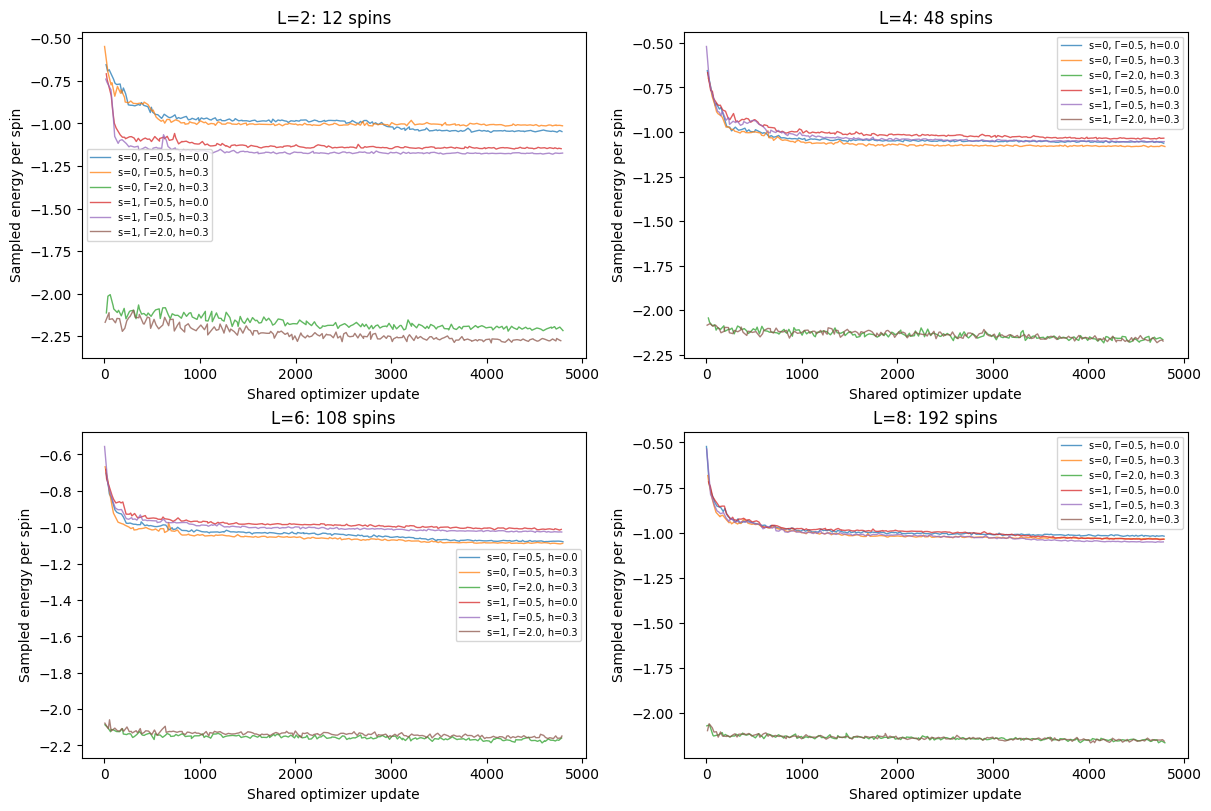

In [2]:
if history:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    for ax, L in zip(axes.flat, (2, 4, 6, 8)):
        contexts = sorted({(r['sample_id'], r['gamma'], r['h']) for r in history if r['L'] == L})
        for sample_id, gamma, h in contexts:
            rows = [r for r in history if (r['L'], r['sample_id'], r['gamma'], r['h']) == (L, sample_id, gamma, h)]
            ax.plot([r['step'] for r in rows], [r['energy']/(3*L*L) for r in rows],
                    label=f's={sample_id}, Γ={gamma}, h={h}', alpha=0.75, linewidth=1)
        ax.set(title=f'L={L}: {3*L*L} spins', xlabel='Shared optimizer update', ylabel='Sampled energy per spin')
        ax.legend(fontsize=7)
    plt.show()
else:
    display(Markdown('Training curves will appear here when `history.json` is available.'))

In [3]:
if evaluation:
    lines = ['| L | Spins | Disorder | VMC E/N ± SE | Raw ⟨q²⟩ ± SE | Connected χ ± SE | Exact E₀/N |',
             '|---|---:|---|---|---|---|---|']
    for r in evaluation:
        n = 3*r['L']**2
        v = r['vmc']
        def estimate(item, scale=1):
            return f"{item['mean']/scale:.6f} ± {item['se']/scale:.6f}"
        exact = f"{r['exact']['energy']/n:.6f}" if 'exact' in r else 'Unavailable'
        split = 'held out' if r['held_out_disorder'] else 'training'
        lines.append(f"| {r['L']} | {n} | ID {r['sample_id']} ({split}) | {estimate(v['energy'], n)} | {estimate(v['q2'])} | {estimate(v['chi_connected'])} | {exact} |")
    display(Markdown('All displayed evaluation points use Γ=0.5 and h=0.3.\n\n' + '\n'.join(lines)))
    display(Markdown('**Interpretation:** these are variational measurements at individual disorder realizations. They are not projected ground-state estimates or disorder-averaged phase-transition evidence.'))
else:
    display(Markdown('The comparison table will appear here when `evaluation.json` is available.'))

All displayed evaluation points use Γ=0.5 and h=0.3.

| L | Spins | Disorder | VMC E/N ± SE | Raw ⟨q²⟩ ± SE | Connected χ ± SE | Exact E₀/N |
|---|---:|---|---|---|---|---|
| 2 | 12 | ID 0 (training) | -1.012209 ± 0.000821 | 0.309435 ± 0.005997 | 0.604818 ± 0.024983 | -1.111915 |
| 2 | 12 | ID 2 (held out) | -0.915768 ± 0.003195 | 0.278537 ± 0.004890 | 0.759603 ± 0.024890 | -1.049923 |
| 4 | 48 | ID 0 (training) | -1.080037 ± 0.000349 | 0.593249 ± 0.002834 | 0.127035 ± 0.004845 | Unavailable |
| 4 | 48 | ID 2 (held out) | -0.913247 ± 0.001850 | 0.390756 ± 0.002840 | 0.350260 ± 0.014994 | Unavailable |
| 6 | 108 | ID 0 (training) | -1.088752 ± 0.000321 | 0.579621 ± 0.002261 | 0.147967 ± 0.005326 | Unavailable |
| 6 | 108 | ID 2 (held out) | -0.937005 ± 0.001155 | 0.499879 ± 0.003056 | 0.240126 ± 0.007880 | Unavailable |
| 8 | 192 | ID 0 (training) | -1.034134 ± 0.000425 | 0.546879 ± 0.001369 | 0.153442 ± 0.004610 | Unavailable |
| 8 | 192 | ID 2 (held out) | -0.906043 ± 0.000731 | 0.408303 ± 0.001671 | 0.329051 ± 0.010724 | Unavailable |

**Interpretation:** these are variational measurements at individual disorder realizations. They are not projected ground-state estimates or disorder-averaged phase-transition evidence.

In [4]:
fixed_paths = sorted((CAMPAIGN_ROOT / 'fixed_size').glob('*/evaluation.json'))
if fixed_paths:
    lines = ['| L | Γ | h | Training seed | Fixed-model E/N ± SE | Local-energy variance/N |',
             '|---|---|---|---:|---|---|']
    for path in fixed_paths:
        settings = json.loads((path.parent / 'settings.json').read_text())
        result = json.loads(path.read_text())
        n = 3*settings['L']**2
        energy = result['energy']
        lines.append(f"| {settings['L']} | {settings['gamma']} | {settings['h']} | {settings['train_seed']} | {energy['mean']/n:.6f} ± {energy['se']/n:.6f} | {result['local_energy_variance']/n:.6f} |")
    display(Markdown('### Fixed-size baseline: completed evaluations\n\n' + '\n'.join(lines)))
    display(Markdown('All fixed-size points use disorder ID 0. Compare with the matching unified ID 0 point; optimization budgets and conditioning differ.'))
else:
    display(Markdown('Fixed-size evaluations are pending download to the campaign directory.'))

### Fixed-size baseline: completed evaluations

| L | Γ | h | Training seed | Fixed-model E/N ± SE | Local-energy variance/N |
|---|---|---|---:|---|---|
| 2 | 0.5 | 0.3 | 18 | -1.111962 ± 0.000372 | 0.004383 |
| 4 | 0.5 | 0.3 | 19 | -1.050501 ± 0.000675 | 0.022942 |
| 6 | 0.5 | 0.0 | 23 | -1.069679 ± 0.000359 | 0.030139 |
| 6 | 0.5 | 0.3 | 21 | -1.076243 ± 0.000548 | 0.028186 |
| 6 | 0.5 | 0.3 | 22 | -1.084195 ± 0.000312 | 0.023627 |
| 6 | 2.0 | 0.3 | 20 | -2.166849 ± 0.001481 | 0.658318 |
| 8 | 0.5 | 0.3 | 24 | -1.054951 ± 0.000269 | 0.038389 |

All fixed-size points use disorder ID 0. Compare with the matching unified ID 0 point; optimization budgets and conditioning differ.